# I.2 — Descriptive statistics of the P&D events

**Objective (brief I.2).** Describe how events are distributed by exchange, pair, channel and period (month,
weekday, UTC hour); count pumps per channel and per coin; compare the capitalisation of targets with that of all
listed coins (Kolmogorov–Smirnov test).

**Data.** The authors' cleaned log (all 1 335 rows) and the CoinGecko snapshots taken three days before each pump.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

settings.seed_everything()
R = Reporter("I2_descriptive_statistics")
log = pd_log.load_pd_log()
log["channel"] = log.channel_id.map(pd_log.channel_labels(log.channel_id))
md(f"{len(log)} rows, {log.channel_id.nunique()} channels, {log.coin.nunique()} coins, "
   f"{log.exchange.nunique()} exchanges, from {log.timestamp.min():%Y-%m-%d} to {log.timestamp.max():%Y-%m-%d}.")

1335 rows, 108 channels, 277 coins, 14 exchanges, from 2019-01-01 to 2022-01-19.

## 1. Exchanges and pairs

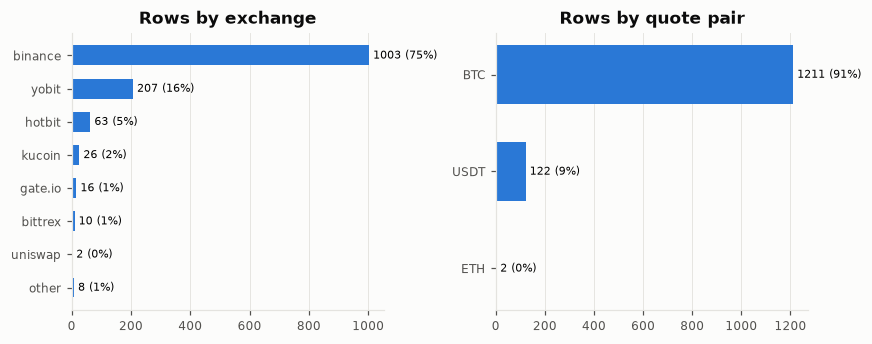

Binance hosts **75.1%** of rows and BTC is the quote of **90.7%** of rows, as stated in the brief (75 % and 91 %).

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
ex = log.exchange.value_counts()
top = ex.head(7)
other = pd.Series({"other": ex.iloc[7:].sum()}) if len(ex) > 7 else pd.Series(dtype=int)
ex_plot = pd.concat([top, other])
axes[0].barh(ex_plot.index[::-1], ex_plot.values[::-1], color=SERIES[0], height=0.6)
axes[0].set_title("Rows by exchange")
for y, v in enumerate(ex_plot.values[::-1]):
    axes[0].text(v, y, f" {v} ({v / len(log):.0%})", va="center", fontsize=7)
pr = log.pair.value_counts()
axes[1].barh(pr.index[::-1], pr.values[::-1], color=SERIES[0], height=0.6)
axes[1].set_title("Rows by quote pair")
for y, v in enumerate(pr.values[::-1]):
    axes[1].text(v, y, f" {v} ({v / len(log):.0%})", va="center", fontsize=7)
for a in axes:
    a.grid(axis="y", visible=False)
R.fig(fig, "exchange_pair")
close(fig)
R.table(pd.DataFrame({"rows": ex, "share": ex / len(log)}), "by_exchange")
md(f"Binance hosts **{ex.get('binance', 0) / len(log):.1%}** of rows and BTC is the quote of "
   f"**{pr.get('BTC', 0) / len(log):.1%}** of rows, as stated in the brief (75 % and 91 %).")

## 2. Time: month, weekday, UTC hour

**Uniformity tests.** For a categorical variable with $K$ classes, observed counts $O_k$ and expected counts
$E_k=n/K$ under $H_0$: "every class is equally likely", Pearson's statistic is
$$\chi^2=\sum_{k=1}^{K}\frac{(O_k-E_k)^2}{E_k}\ \overset{H_0}{\sim}\ \chi^2_{K-1}.$$
The effect size is Cramér's $V=\sqrt{\chi^2/(n(K-1))}$. The test assumes independent rows; relayed announcements of
the same pump violate it, so we also run it on de-duplicated events (one row per coin, exchange, hour).

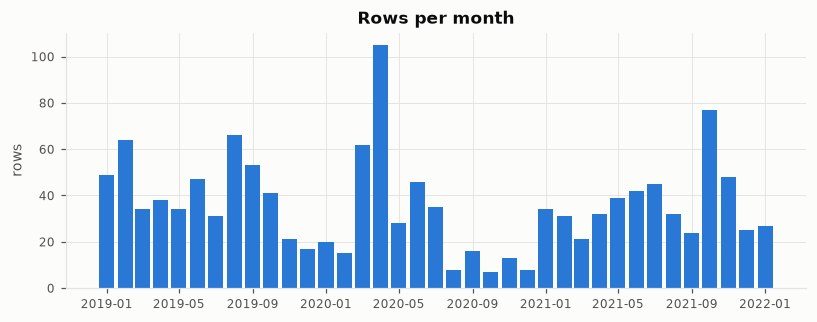

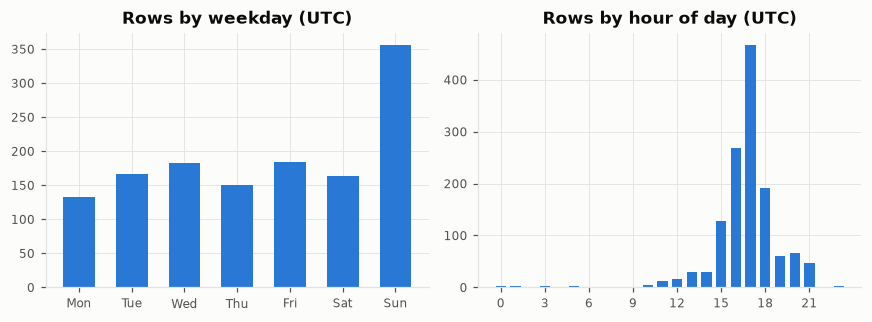

,unit,variable,n,K,chi2,df,p,Cramer V
0,rows,weekday,1335,7,177.3,6,1.245e-35,0.1488
1,rows,hour,1335,24,5055,23,0,0.4058
2,events,weekday,730,7,34.82,6,4.666e-06,0.08916
3,events,hour,730,24,2336,23,0,0.373


- weekday (rows): $\chi^2(6)=177.3,\ p=1.25\times10^{-35}$, $V=0.15$ → reject $H_0$ at $\alpha=0.05$.

- hour (rows): $\chi^2(23)=5055.3,\ p<10^{-300}$, $V=0.41$ → reject $H_0$ at $\alpha=0.05$.

- weekday (events): $\chi^2(6)=34.8,\ p=4.67\times10^{-6}$, $V=0.09$ → reject $H_0$ at $\alpha=0.05$.

- hour (events): $\chi^2(23)=2335.6,\ p<10^{-300}$, $V=0.37$ → reject $H_0$ at $\alpha=0.05$.

The three busiest UTC hours are 17:00 (467 rows), 16:00 (269 rows), 18:00 (191 rows): pumps are scheduled on round hours chosen to suit a global audience, so the hour distribution is very far from uniform.

In [3]:
log["month"] = log.timestamp.dt.to_period("M").dt.to_timestamp()
log["weekday"] = log.timestamp.dt.day_name().str[:3]
log["hour"] = log.timestamp.dt.hour
events = log.assign(h=log.timestamp.dt.floor("h")).drop_duplicates(["coin", "exchange", "h"])
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7.5, 3))
m = log.groupby("month").size()
ax.bar(m.index, m.values, width=25, color=SERIES[0])
ax.set_title("Rows per month")
ax.set_ylabel("rows")
R.fig(fig, "by_month")
close(fig)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
wd = log.weekday.value_counts().reindex(order)
axes[0].bar(wd.index, wd.values, color=SERIES[0], width=0.6)
axes[0].set_title("Rows by weekday (UTC)")
hr = log.hour.value_counts().reindex(range(24), fill_value=0)
axes[1].bar(hr.index, hr.values, color=SERIES[0], width=0.7)
axes[1].set_title("Rows by hour of day (UTC)")
axes[1].set_xticks(range(0, 24, 3))
R.fig(fig, "weekday_hour")
close(fig)

rows = []
for name, df in (("rows", log), ("events", events)):
    for var, cats in (("weekday", order), ("hour", list(range(24)))):
        obs = df[var].value_counts().reindex(cats, fill_value=0).values
        chi2, p = st.chisquare(obs)
        rows.append({"unit": name, "variable": var, "n": obs.sum(), "K": len(cats), "chi2": chi2, "df": len(cats) - 1,
                     "p": p, "Cramer V": np.sqrt(chi2 / (obs.sum() * (len(cats) - 1)))})
chi = pd.DataFrame(rows)
R.table(chi, "chi2_uniformity", index=False)
show(chi)
for r in chi.itertuples():
    md(f"- {r.variable} ({r.unit}): $\\chi^2({r.df})={r.chi2:.1f},\\ {S.fmt_p(r.p)}$, $V={r._8:.2f}$ → {S.decision(r.p)}.")
top_hours = hr.sort_values(ascending=False).head(3)
md(f"The three busiest UTC hours are {', '.join(f'{h}:00 ({v} rows)' for h, v in top_hours.items())}: pumps are "
   "scheduled on round hours chosen to suit a global audience, so the hour distribution is very far from uniform.")

## 3. Pumps per channel and per coin

**Concentration.** For counts $x_{(1)}\le\dots\le x_{(n)}$ the Lorenz curve is
$L(k/n)=\sum_{i\le k}x_{(i)}/\sum_i x_i$ and the Gini coefficient
$$G=\frac{\sum_{i=1}^{n}(2i-n-1)\,x_{(i)}}{n\sum_i x_i}\in[0,1),$$
with $G=0$ for equal counts.

,units,mean,median,max,Gini,share of rows from top 10%
channels,108,12.36,6,95,0.5701,0.4037
coins,277,4.819,1,40,0.6146,0.4667


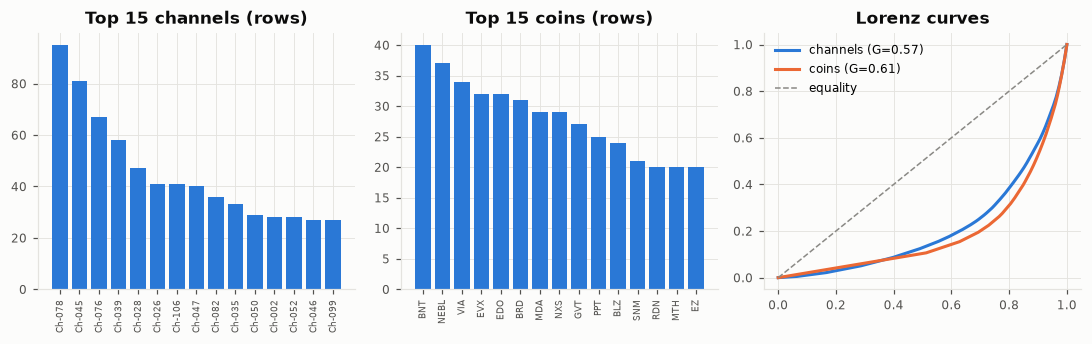

48.7% of coins appear more than once; channels are strongly concentrated ($G_{channels}=0.57$) and so are coins ($G_{coins}=0.61$). Repeated targets are the regularity that sequence models exploit.

In [4]:
per_channel = log.channel.value_counts()
per_coin = log.coin.value_counts()
conc = pd.DataFrame({
    "units": [len(per_channel), len(per_coin)], "mean": [per_channel.mean(), per_coin.mean()],
    "median": [per_channel.median(), per_coin.median()], "max": [per_channel.max(), per_coin.max()],
    "Gini": [S.gini(per_channel), S.gini(per_coin)],
    "share of rows from top 10%": [per_channel.head(max(1, len(per_channel) // 10)).sum() / len(log),
                                   per_coin.head(max(1, len(per_coin) // 10)).sum() / len(log)],
}, index=["channels", "coins"])
R.table(conc, "concentration")
show(conc)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].bar(range(15), per_channel.head(15).values, color=SERIES[0])
axes[0].set_xticks(range(15), per_channel.head(15).index, rotation=90, fontsize=6)
axes[0].set_title("Top 15 channels (rows)")
axes[1].bar(range(15), per_coin.head(15).values, color=SERIES[0])
axes[1].set_xticks(range(15), per_coin.head(15).index, rotation=90, fontsize=6)
axes[1].set_title("Top 15 coins (rows)")
for s, lab, c in ((per_channel, "channels", SERIES[0]), (per_coin, "coins", SERIES[1])):
    x = np.sort(s.values)
    L = np.concatenate([[0], np.cumsum(x) / x.sum()])
    axes[2].plot(np.linspace(0, 1, len(L)), L, label=f"{lab} (G={S.gini(x):.2f})", color=c)
axes[2].plot([0, 1], [0, 1], color="#8a8985", lw=1, ls="--", label="equality")
axes[2].set_title("Lorenz curves")
axes[2].legend()
R.fig(fig, "concentration")
close(fig)
repump = (per_coin > 1).mean()
md(f"{repump:.1%} of coins appear more than once; channels are strongly concentrated "
   f"($G_{{channels}}={S.gini(per_channel):.2f}$) and so are coins ($G_{{coins}}={S.gini(per_coin):.2f}$). "
   "Repeated targets are the regularity that sequence models exploit.")

## 4. Capitalisation of targets versus listed coins

Let $X$ be the log market capitalisation (USD) of a pump target three days before the pump and $Y$ that of a coin
listed on Binance at the same dates (the authors' candidate coins). With empirical CDFs $F_n$ and $G_m$, the
two-sample Kolmogorov–Smirnov statistic is
$$D_{n,m}=\sup_x\,|F_n(x)-G_m(x)|,$$
and under $H_0: F=G$ (continuous), $\sqrt{nm/(n+m)}\,D_{n,m}$ converges to the Kolmogorov distribution. We
complement it with the Mann–Whitney $U$ test ($H_0$: $P(X>Y)=1/2$, effect size $\hat\theta=U/(nm)$) and the
Anderson–Darling $k$-sample test, which is more sensitive in the tails.

A pooled comparison mixes dates; we therefore also compute, per event, the **percentile of the target inside its
own candidate set**, $u_i=\hat G_{i}(x_i)$. Under $H_0$ "targets are drawn like any listed coin", $u_i\sim U(0,1)$,
which a one-sample KS test checks.

In [5]:
gk = coingecko.load_all()
tg = gk[gk.source == "targets"].dropna(subset=["market_cap_usd"])
cd = gk[gk.source == "candidates"].dropna(subset=["market_cap_usd"])
x = np.log10(tg.market_cap_usd.values)
y = np.log10(cd.market_cap_usd.values)
ks = st.ks_2samp(x, y)
mw = st.mannwhitneyu(x, y, alternative="two-sided")
ad = st.anderson_ksamp([x, y])
tests = pd.DataFrame({"statistic": [ks.statistic, mw.statistic / (len(x) * len(y)), ad.statistic],
                      "p": [ks.pvalue, mw.pvalue, ad.pvalue]},
                     index=["KS D", "Mann-Whitney theta=U/(nm)", "Anderson-Darling"])
R.table(tests, "mcap_tests")
show(tests)
md(f"Targets: $n={len(x)}$, median capitalisation **USD {10 ** np.median(x) / 1e6:.1f}M**; listed coins: $m={len(y)}$, "
   f"median **USD {10 ** np.median(y) / 1e6:.1f}M**.\n\n"
   f"KS: $D={ks.statistic:.3f},\\ {S.fmt_p(ks.pvalue)}$ → {S.decision(ks.pvalue)}. Mann–Whitney: "
   f"$\\hat\\theta=P(X>Y)={mw.statistic / (len(x) * len(y)):.3f},\\ {S.fmt_p(mw.pvalue)}$. "
   f"Anderson–Darling: $A^2={ad.statistic:.1f}$ (scipy caps its p-value at 0.001: $p\\le{ad.pvalue:.3f}$).")

,statistic,p
KS D,0.4237,1.854e-87
Mann-Whitney theta=U/(nm),0.255,1.392e-85
Anderson-Darling,256.7,0.001


Targets: $n=538$, median capitalisation **USD 14.2M**; listed coins: $m=63784$, median **USD 67.1M**.

KS: $D=0.424,\ p=1.85\times10^{-87}$ → reject $H_0$ at $\alpha=0.05$. Mann–Whitney: $\hat\theta=P(X>Y)=0.255,\ p=1.39\times10^{-85}$. Anderson–Darling: $A^2=256.7$ (scipy caps its p-value at 0.001: $p\le0.001$).

Per-event percentile of the target among same-date listed coins ($N=447$): quartiles 0.09 / 0.23 / 0.41; one-sample KS against $U(0,1)$: $D=0.345,\ p=4.59\times10^{-48}$ → reject $H_0$ at $\alpha=0.05$.

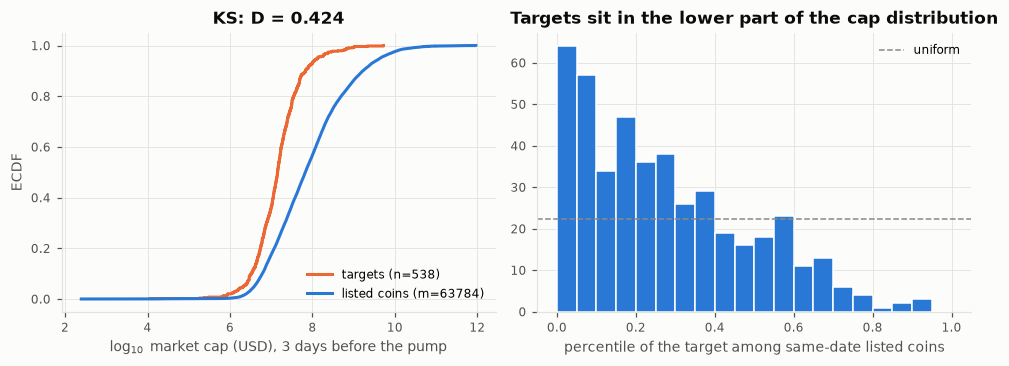

In [6]:
pct = []
for (coin, date), g in tg.groupby(["coin", "pump_date"]):
    pool = cd[cd.pump_date == date].market_cap_usd.values
    if len(pool) >= 20:
        pct.append((pool < g.market_cap_usd.iloc[0]).mean())
pct = np.array(pct)
ks1 = st.kstest(pct, "uniform")
q = np.quantile(pct, [0.25, 0.5, 0.75])
md(f"Per-event percentile of the target among same-date listed coins ($N={len(pct)}$): quartiles "
   f"{q[0]:.2f} / {q[1]:.2f} / {q[2]:.2f}; one-sample KS against $U(0,1)$: $D={ks1.statistic:.3f},\\ {S.fmt_p(ks1.pvalue)}$ "
   f"→ {S.decision(ks1.pvalue)}.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for v, lab, c in ((x, f"targets (n={len(x)})", SERIES[1]), (y, f"listed coins (m={len(y)})", SERIES[0])):
    s = np.sort(v)
    axes[0].step(s, np.arange(1, len(s) + 1) / len(s), where="post", label=lab, color=c)
axes[0].set_xlabel(r"$\log_{10}$ market cap (USD), 3 days before the pump")
axes[0].set_ylabel("ECDF")
axes[0].set_title(f"KS: D = {ks.statistic:.3f}")
axes[0].legend(loc="lower right")
axes[1].hist(pct, bins=20, range=(0, 1), color=SERIES[0], edgecolor="white")
axes[1].axhline(len(pct) / 20, color="#8a8985", ls="--", lw=1, label="uniform")
axes[1].set_xlabel("percentile of the target among same-date listed coins")
axes[1].set_title("Targets sit in the lower part of the cap distribution")
axes[1].legend()
R.fig(fig, "mcap_ecdf")
close(fig)

## 5. Interpretation

* **Platforms and pairs.** Activity is concentrated on Binance and on BTC pairs, the exchange with the deepest
  liquidity and the quote currency the organisers' members already hold.
* **Timing.** Pumps are scheduled, not random: the hour-of-day distribution is extremely concentrated on a few
  round UTC hours (17:00 UTC alone carries about a third of the rows), and the weekday distribution is uneven
  too: Sunday carries about twice the rows of any other day. The $\chi^2$ tests reject uniformity on rows and on
  de-duplicated events, although the weekday effect size is small ($V<0.15$) while the hour effect is large.
* **Concentration.** A small number of channels produces most of the rows and many coins are pumped repeatedly —
  the paper reports a 60.1 % re-pump probability.
* **Capitalisation.** Target and listed-coin capitalisations differ significantly: the median target is about
  five times smaller than the median listed coin, and $P(X>Y)\approx0.26$. The per-event percentiles show *where*:
  targets lie mostly between the 10th and the 40th percentile of the coins listed on the same day. They avoid
  the large caps (too expensive to move) without concentrating on the very smallest coins (too illiquid to exit):
  the "small-to-mid cap" preference discussed in I.1. Note that "listed coins" here are the coins listed on
  **Binance**, an exchange that already excludes the micro-caps of the wider market.

**Limitations.** CoinGecko capitalisation is missing for some coins (see I.0); the pooled tests treat rows as
independent although relayed announcements of one pump are not, which the event-level and per-event analyses
address.